In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, recall_score, confusion_matrix, precision_score, f1_score, classification_report
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

In [3]:
df = pd.read_csv("../../../../datasets/Telco_Customer_Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [8]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

<Axes: >

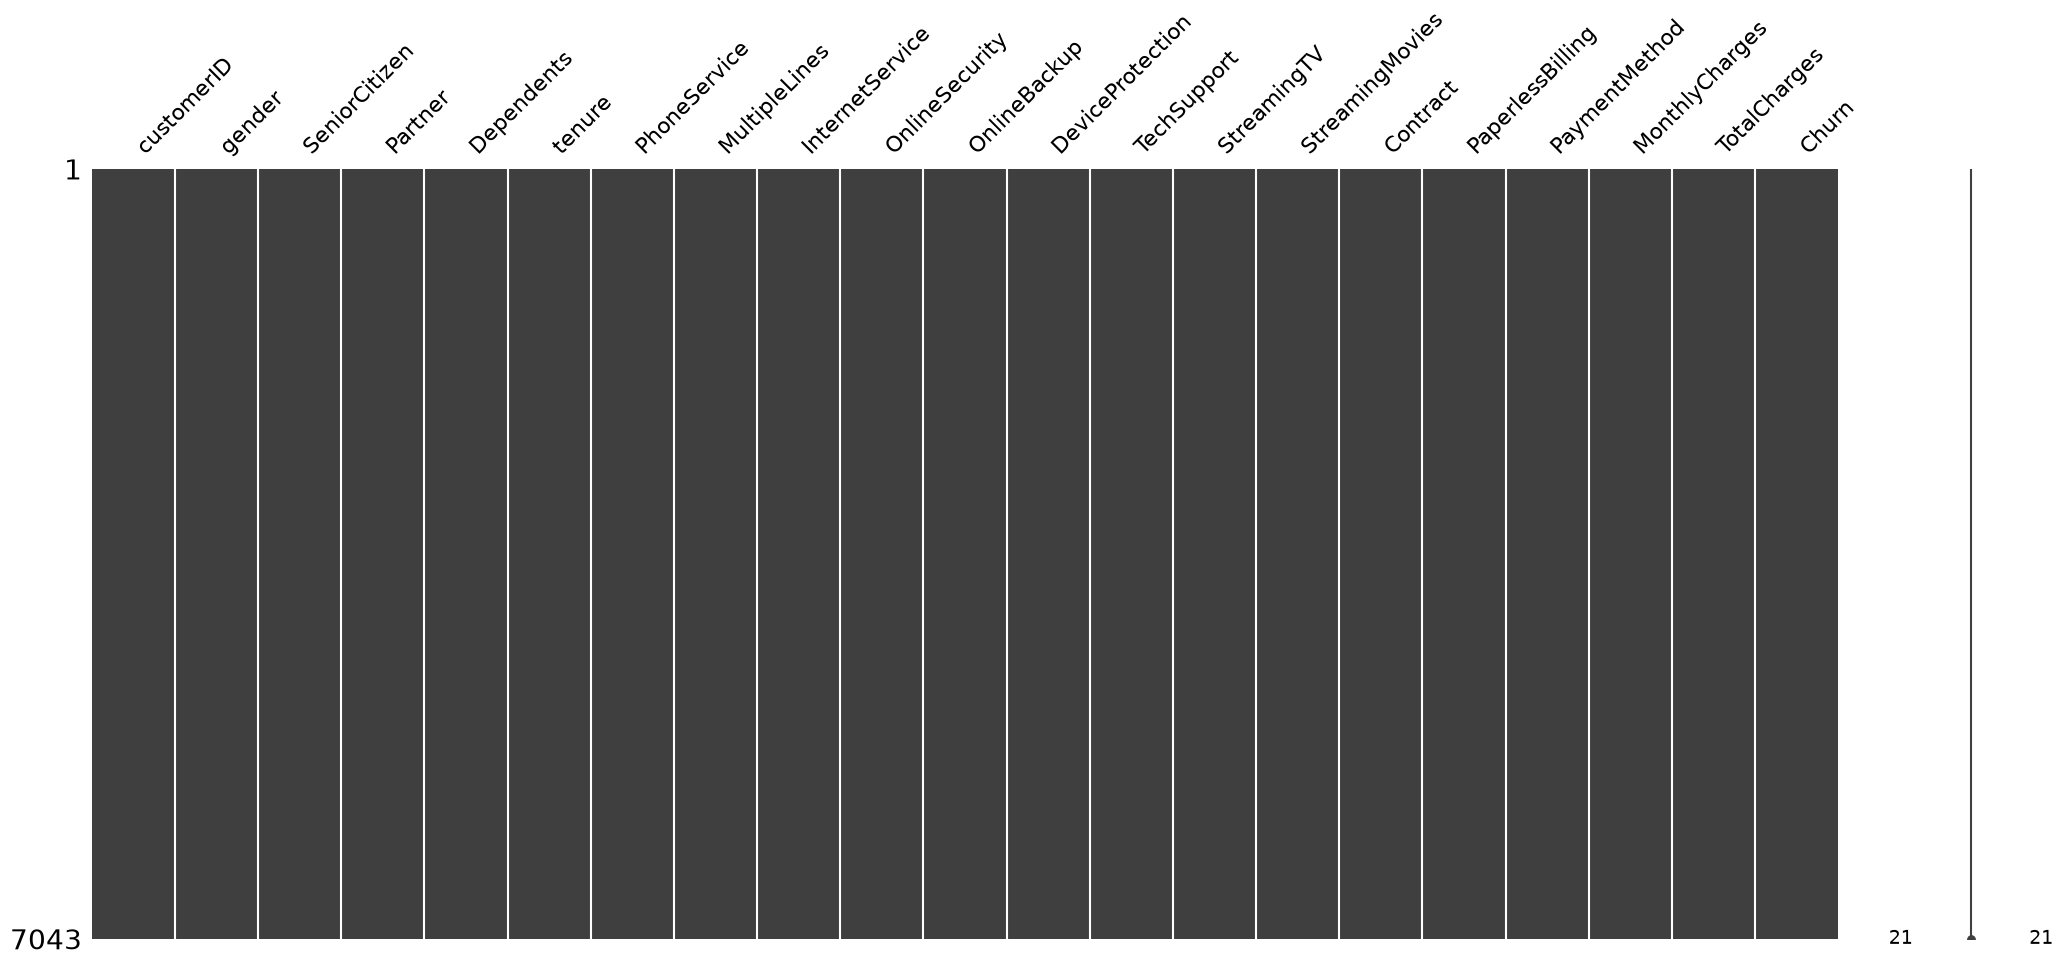

In [9]:
msno.matrix(df)

In [10]:
df = df.drop(['customerID'], axis = 1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce')
df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
df[np.isnan(df['TotalCharges'])]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [13]:
df[df['tenure'] == 0].index

Index([488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754], dtype='int64')

In [14]:
df.drop(labels=df[df['tenure'] == 0].index, axis=0, inplace=True)
df[df['tenure'] == 0].index

Index([], dtype='int64')

In [15]:
df.fillna(df['TotalCharges'].mean())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [16]:
df.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [17]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
df["InternetService"].describe(include=['object', 'bool'])

count            7032
unique              3
top       Fiber optic
freq             3096
Name: InternetService, dtype: object

In [19]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[numerical_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [20]:
g_labels = ['Male', 'Female']
c_labels = ['No', 'Yes']

fig = make_subplots(rows=1, cols=2, specs=[[{'type': 'domain'}, {'type': 'domain'}]])
fig.add_trace(go.Pie(labels=g_labels, values=df['gender'].value_counts(), name="Gender"), 1, 1)
fig.add_trace(go.Pie(labels=c_labels, values=df['Churn'].value_counts(), name="Churn"), 1, 2)

fig.update_traces(hole=.4, hoverinfo="label+percent+name", textfont_size=16)

fig.update_layout(
    title_text="Gender and Churn Distributions",
    annotations=[
        dict(text='Gender', x=0.16, y=0.5, font_size=20, showarrow=False),
        dict(text='Churn', x=0.84, y=0.5, font_size=20, showarrow=False)
    ]
)
fig.show()

In [21]:
df["Churn"][df["Churn"] == "No"].groupby(by=df["gender"]).count()

gender
Female    2544
Male      2619
Name: Churn, dtype: int64

In [22]:
df["Churn"][df["Churn"] == "Yes"].groupby(by=df["gender"]).count()

gender
Female    939
Male      930
Name: Churn, dtype: int64

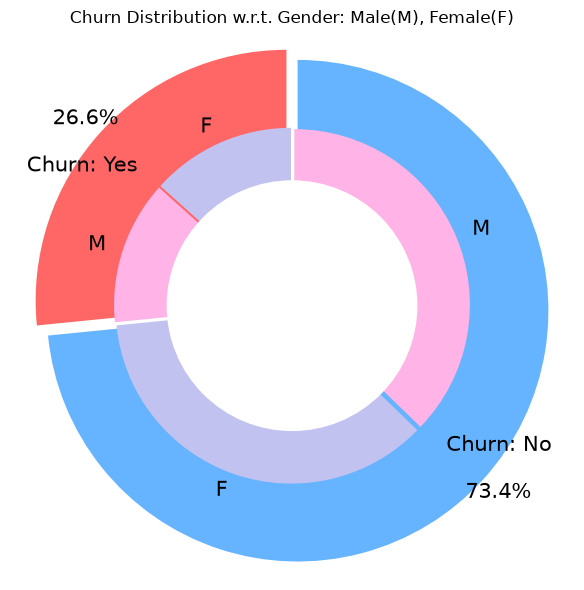

In [23]:
plt.figure(figsize=(6,6))
labels = ["Churn: Yes", "Churn: No"]
values = [1869, 5163]
labels_gender = ["F", "M", "F", "M"]
sizes_gender = [939, 930, 2544, 2619]
colors = ['#ff6666', '#66b3ff']
colors_gender = ['#c2c2f0','#ffb3e6', '#c2c2f0','#ffb3e6']
explode = (0.3, 0.3)
explode_gender = (0.1, 0.1, 0.1, 0.1)
textprops = {"fontsize": 15}

plt.pie(
    values, 
    labels=labels, 
    autopct='%1.1f%%',
    pctdistance=1.08, 
    labeldistance=0.8, 
    colors=colors, 
    startangle=90, 
    frame=True, 
    explode=explode, 
    radius=10,
    textprops=textprops,
    counterclock=True
)
plt.pie(
    sizes_gender,
    labels=labels_gender,
    colors=colors_gender,
    startangle=90,
    explode=explode_gender,
    radius=7,
    textprops=textprops,
    counterclock=True
)
center_circle = plt.Circle((0, 0), 5, color='black',fc='white', linewidth=0)
fig = plt.gcf()
fig.gca().add_artist(center_circle)

plt.title('Churn Distribution w.r.t. Gender: Male(M), Female(F)')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [24]:
fig = px.histogram(df, x="Churn", color="Contract", barmode="group", title="Customer contract distribution")
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [25]:
labels = df['PaymentMethod'].unique()
values = df["PaymentMethod"].value_counts()

fig = go.Figure(data=[go.Pie(labels=labels, values=values, hole=.3)])
fig.update_layout(title_text="Payment Method Distribution")
fig.show()

In [26]:
fig = px.histogram(df, x="Churn", color="PaymentMethod", title="Customer Payment Method distribution w.r.t. Churn")
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [27]:
df["InternetService"].unique()

<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

In [28]:
df[df["gender"] == "Male"][["InternetService", "Churn"]].value_counts()

InternetService  Churn
DSL              No       992
Fiber optic      No       910
No               No       717
Fiber optic      Yes      633
DSL              Yes      240
No               Yes       57
Name: count, dtype: int64

In [29]:
df[df["gender"] == "Female"][["InternetService", "Churn"]].value_counts()

InternetService  Churn
DSL              No       965
Fiber optic      No       889
No               No       690
Fiber optic      Yes      664
DSL              Yes      219
No               Yes       56
Name: count, dtype: int64

In [30]:
fig = go.Figure()

fig.add_trace(go.Bar(
    x = [['Churn:No', 'Churn:No', 'Churn:Yes', 'Churn:Yes'],
         ["Female", "Male", "Female", "Male"]],
    y = [965, 992, 219, 240],
    name = "DSL",
))

fig.add_trace(go.Bar(
    x = [['Churn:No', 'Churn:No', 'Churn:Yes', 'Churn:Yes'],
         ["Female", "Male", "Female", "Male"]],
    y = [889, 910, 664, 633],
    name = "Fiber optic",
))

fig.add_trace(go.Bar(
    x = [['Churn:No', 'Churn:No', 'Churn:Yes', 'Churn:Yes'],
         ["Female", "Male", "Female", "Male"]],
    y = [690, 717, 56, 57],
    name = "No Internet",
))

fig.update_layout(title_text="Churn Distribution w.r.t. Internet Service and Gender")
fig.show()



In [31]:
color_map = {"Yes": "coral", "No": "violet"}
fig = px.histogram(
    df, 
    x="Churn", 
    color="Dependents", 
    barmode="group", 
    title="Dependents distribution",
    color_discrete_map=color_map
)
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [32]:
color_map = {"Yes": 'orange', "No":"green"}
fig = px.histogram(
    df,
    x="Churn",
    color="Partner",
    barmode="group",
    title="Churn distribution w.r.t. Partners",
    color_discrete_map=color_map
)
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [33]:
color_map = {"Yes": "yellow", "No":"coral"}
fig = px.histogram(
    df,
    x="Churn",
    color="SeniorCitizen",
    title="Churn distribtion w.r.t. Senior Citizen",
    color_discrete_map=color_map
)
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [34]:
def plot_bar_graph(df, x_data, color_data, title_name):
    color_map = {"Yes": '#FFA15A', "No": '#00CC96'}
    fig = px.histogram(df, x=x_data, color=color_data, barmode="group", title=f"<b>{title_name}</b>", color_discrete_map=color_map)
    fig.update_layout(width=700, height=500, bargap=0.1)
    fig.show()

In [35]:
plot_bar_graph(df, "Churn", "OnlineSecurity", "Churn distribution w.r.t. Online Security")

In [36]:
df["OnlineSecurity"].nunique()

3

In [37]:
import plotly.express as px

# 1. Expand your color map to handle all potential categories of Online Security 
# (e.g., 'Yes', 'No', 'No internet service')
color_map = {
    "Yes": "#2b5c8f", 
    "No": "#e76f51", 
    "No internet service": "#e9c46a"
}

# 2. Create the base figure with automatic value labels on bars
fig = px.histogram(
    df, 
    x="Churn", 
    color="OnlineSecurity", 
    barmode="group",
    color_discrete_map=color_map,
    text_auto=True # Automatically displays the exact count on top of each bar
)

# 3. Apply Advanced Layout & Styling
fig.update_layout(
    # Professional Title with a Subtitle
    title={
        'text': "<b>Customer Churn Analysis</b><br><sup>Impact of Online Security Subscription on Churn Rates</sup>",
        'y': 0.92,
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top',
        'font': dict(size=18, family="Inter, sans-serif", color="#1e293b")
    },
    # Axis Customization
    xaxis=dict(
        title="<b>Customer Churn Status</b>",
        title_font=dict(size=13, family="Inter, sans-serif"),
        tickfont=dict(size=12, color="#475569"),
        showgrid=False
    ),
    yaxis=dict(
        title="<b>Number of Customers</b>",
        title_font=dict(size=13, family="Inter, sans-serif"),
        tickfont=dict(size=12, color="#475569"),
        showgrid=True,
        gridcolor="#f1f5f9",
        gridwidth=1
    ),
    # Modern Horizontal Legend positioned neatly at the top right
    legend=dict(
        title="<b>Online Security</b>",
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        bgcolor="rgba(255, 255, 255, 0.9)",
        bordercolor="#cbd5e1",
        borderwidth=1
    ),
    # Clean minimalist canvas background
    plot_bgcolor="white",
    paper_bgcolor="white",
    width=800,
    height=550,
    bargap=0.15,
    bargroupgap=0.05,
    margin=dict(t=100, b=60, l=60, r=40)
)

# 4. Advanced Trace Customization (Clean borders & Custom Hover Tooltip)
fig.update_traces(
    marker=dict(line=dict(width=1.2, color='#ffffff')), # Crisp white border around bars
    textfont=dict(size=11, color="#1e293b"),
    hovertemplate=(
        "<b>Status:</b> %{x}<br>"
        "<b>Online Security:</b> %{fullData.name}<br>"
        "<b>Customer Count:</b> %{y}<br>"
        "<extra></extra>" # Hides the secondary trace box identifier
    )
)

fig.show()

In [38]:
color_map = {"Yes": '#FFA15A', "No": "#00CC96"}
fig = px.histogram(df, x="Churn", color="PaperlessBilling", title="<b>Churn distribution w.r.t. Paperless Billing</b>", color_discrete_map=color_map)
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [39]:
fig = px.histogram(df, x="Churn", color="TechSupport", barmode='group', title="<b>Churn distribution w.r.t. TechSupport</b>")
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [40]:
color_map = {"Yes": "#00CC96", "No": "#B6E880"}
fig = px.histogram(df, x="Churn", color="PhoneService", title="<b>Churn Distribution w.r.t. Phone Service</b>", color_discrete_map=color_map)
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

Text(0.5, 1.0, 'Distribution of monthly charges by churn')

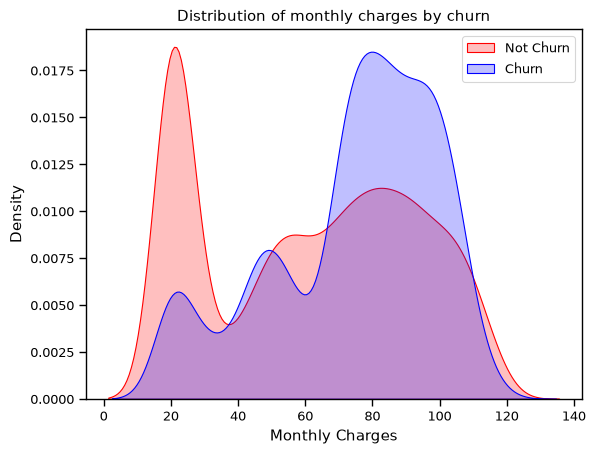

In [41]:
sns.set_context("paper", font_scale=1.1)
ax = sns.kdeplot(df.MonthlyCharges[(df["Churn"] == 'No')],
                 color="Red", shade=True)
ax = sns.kdeplot(df.MonthlyCharges[(df["Churn"] == 'Yes')],
                 color='Blue', shade=True)
ax.legend(['Not Churn', 'Churn'], loc='upper right')
ax.set_ylabel('Density')
ax.set_xlabel('Monthly Charges')
ax.set_title('Distribution of monthly charges by churn')

Text(0.5, 1.0, 'Distribution of total charges by churn')

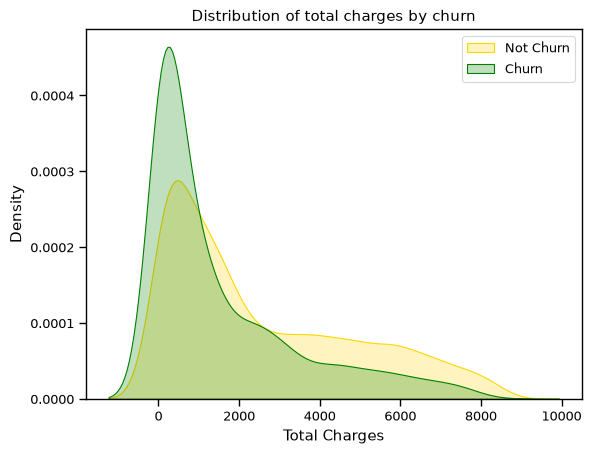

In [42]:
ax = sns.kdeplot(df.TotalCharges[(df["Churn"] == "No")],
                 color="Gold", shade=True)
ax = sns.kdeplot(df.TotalCharges[(df["Churn"] == "Yes")],
                 ax=ax, color="Green", shade=True)
ax.legend(["Not Churn", "Churn"], loc='upper right')
ax.set_ylabel('Density')
ax.set_xlabel('Total Charges')
ax.set_title('Distribution of total charges by churn')

In [43]:
fig = px.box(df, x="Churn", y='tenure')
fig.update_yaxes(title_text='Tenure (Months)', row=1, col=1)
fig.update_xaxes(title_text='Churn', row=1, col=1)

fig.update_layout(autosize=True, width=750, height=600,
                  title_font=dict(size=25, family='Courier'),
                  title="<b>Tenure vs Churn</b>"
)
fig.show()

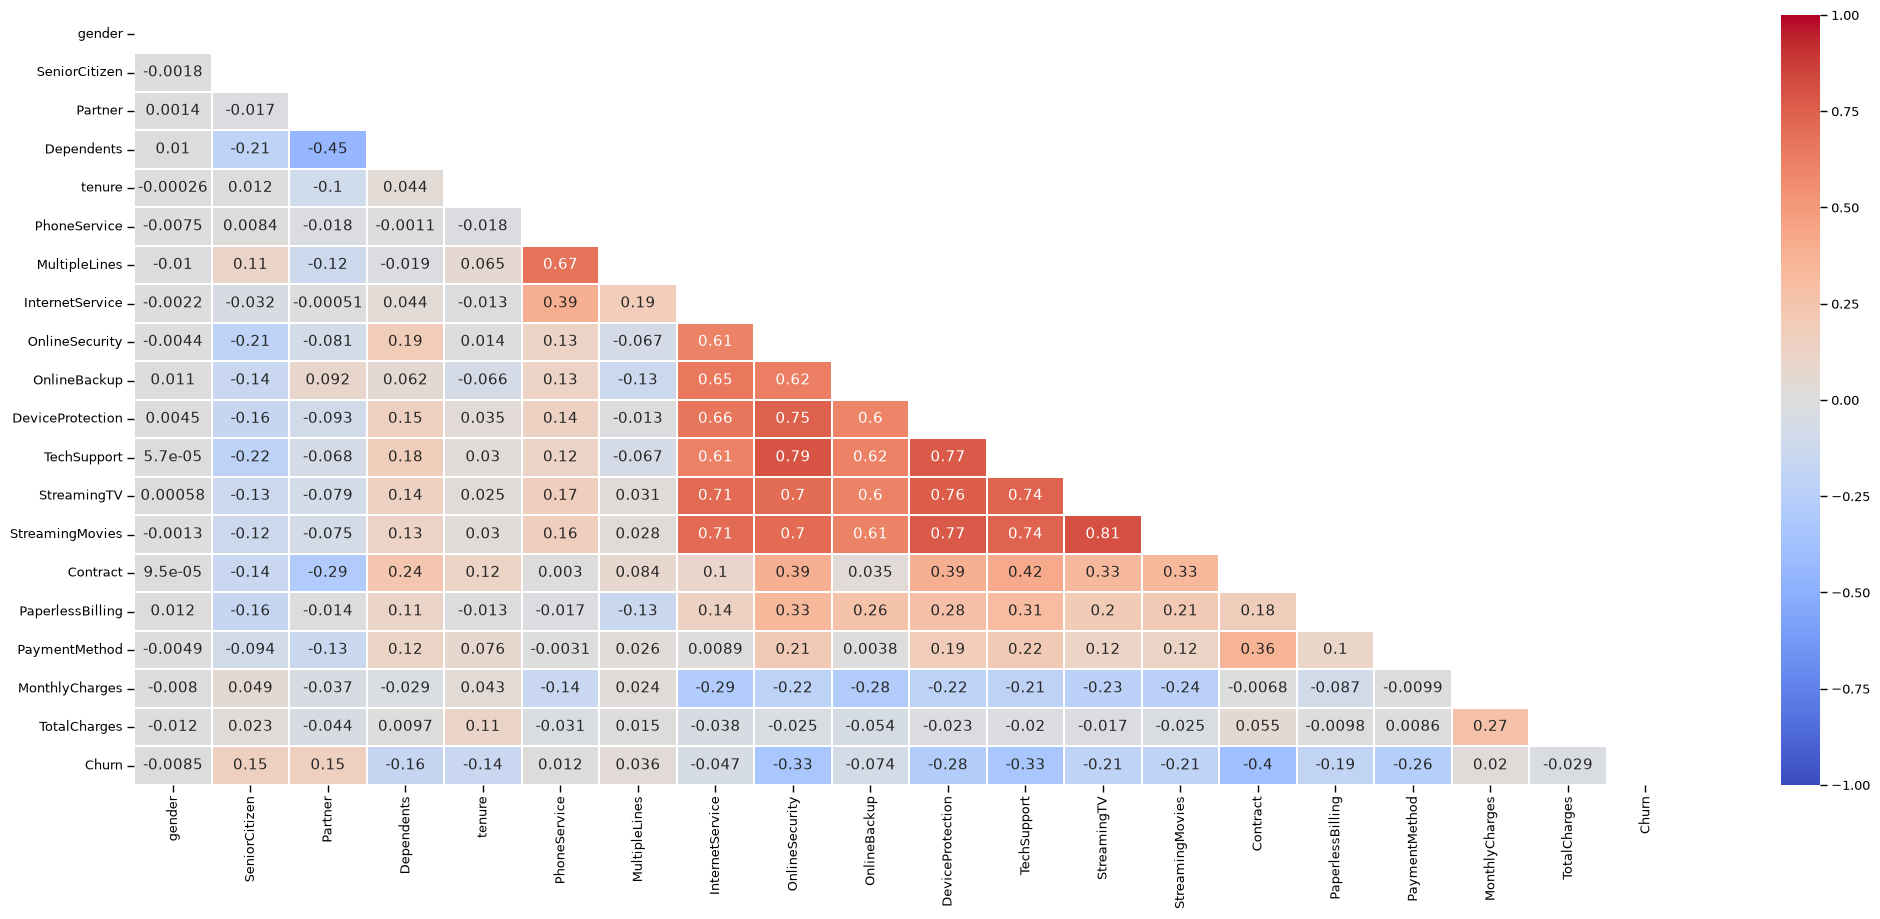

In [44]:
plt.figure(figsize=(25,10))
corr = df.apply(lambda x: pd.factorize(x)[0]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
ax = sns.heatmap(
    corr, mask=mask, 
    xticklabels=corr.columns, 
    yticklabels=corr.columns,
    annot=True,
    linewidths=.2,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
    )

In [45]:
def object_to_int(df_series):
    if df_series.dtype == 'object':
        df_series = LabelEncoder().fit_transform(df_series)
    return df_series

In [46]:
df = df.apply(lambda x: object_to_int(x))
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [47]:
df['gender'] = (df["gender"] == "Male").astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,1,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,1,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,1,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [48]:
yes_no_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "Churn", "MultipleLines"]

df[yes_no_cols] = (df[yes_no_cols] == "Yes").astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [50]:
categorical_cols = ["InternetService", "Contract", "PaymentMethod"]
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)
df.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


In [51]:
plt.figure(figsize=(14, 7))
df.corr()['Churn'].sort_values(ascending=False)

Churn                                    1.000000
InternetService_Fiber optic              0.307463
PaymentMethod_Electronic check           0.301455
MonthlyCharges                           0.192858
PaperlessBilling                         0.191454
SeniorCitizen                            0.150541
StreamingTV                              0.063254
StreamingMovies                          0.060860
MultipleLines                            0.040033
PhoneService                             0.011691
gender                                  -0.008545
DeviceProtection                        -0.066193
OnlineBackup                            -0.082307
PaymentMethod_Mailed check              -0.090773
PaymentMethod_Credit card (automatic)   -0.134687
Partner                                 -0.149982
Dependents                              -0.163128
TechSupport                             -0.164716
OnlineSecurity                          -0.171270
Contract_One year                       -0.178225


<Figure size 1400x700 with 0 Axes>

In [52]:
X, y = df.drop(columns = ['Churn']), df['Churn'].values

In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [64]:
def distplot(feature, frame, color='r'):
    plt.figure(figsize=(8,3))
    ax = sns.displot(frame[feature], color=color)
    plt.title(f"Distribution for {feature}")

<Figure size 800x300 with 0 Axes>

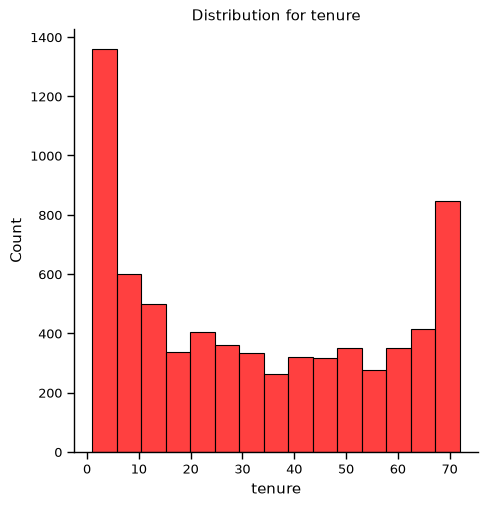

<Figure size 800x300 with 0 Axes>

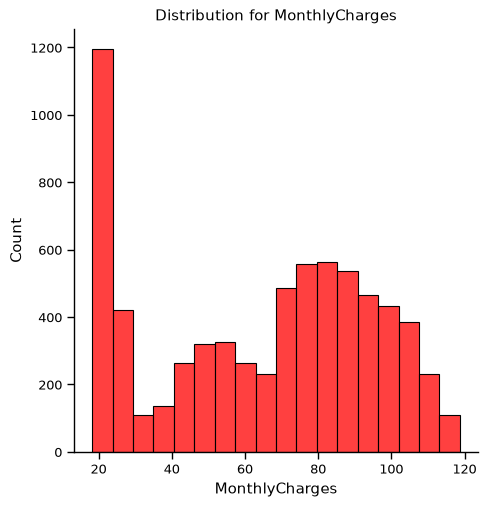

<Figure size 800x300 with 0 Axes>

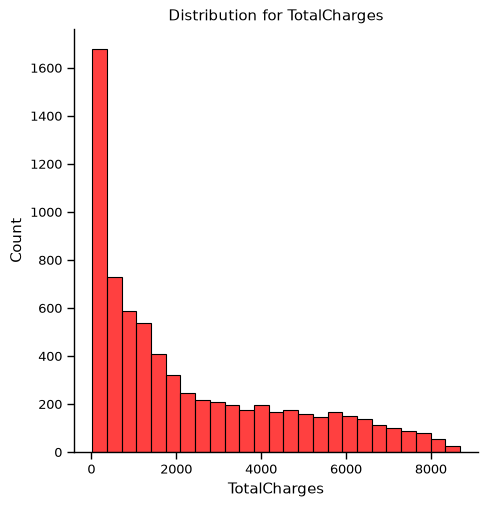

In [65]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for feat in num_cols: distplot(feat, df)

<Figure size 800x300 with 0 Axes>

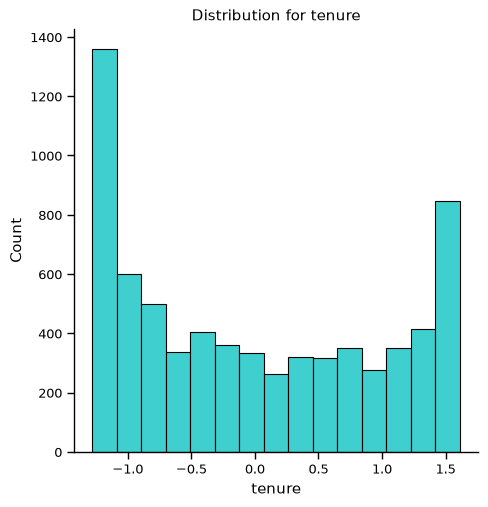

<Figure size 800x300 with 0 Axes>

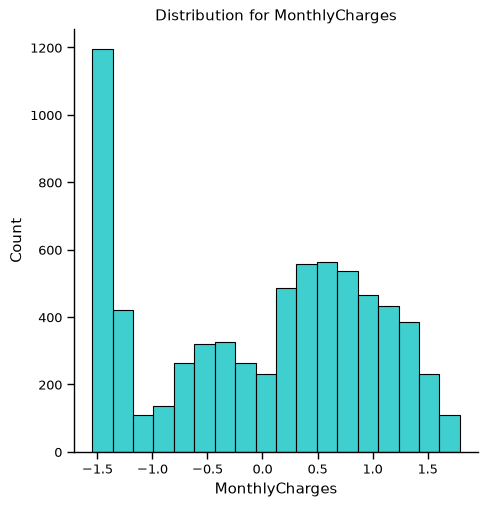

<Figure size 800x300 with 0 Axes>

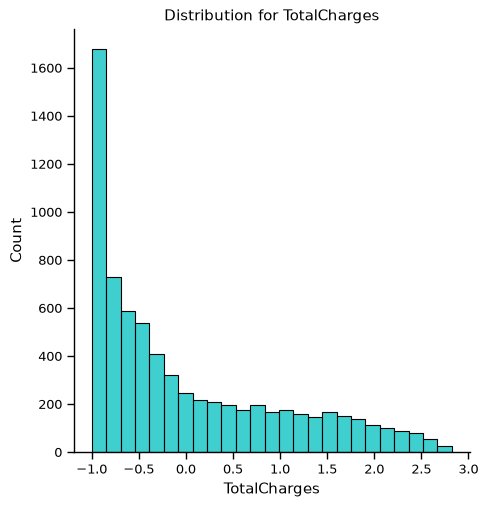

In [66]:
df_std = pd.DataFrame(StandardScaler().fit_transform(df[num_cols].astype('float64')),
                      columns=num_cols)
for feat in numerical_cols: distplot(feat, df_std, color='c')

In [67]:
cat_cols_ohe = ["PaymentMethod", "Contract", "InternetService"]
cat_cols_le = list(set(X_train.columns) - set(num_cols) - set(cat_cols_ohe))

In [68]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [69]:
knn_model = KNeighborsClassifier(n_neighbors=11)
knn_model.fit(X_train, y_train)
pred_y_knn = knn_model.predict(X_test)
acc_knn = knn_model.score(X_test, y_test)
print("KNN Accuracy: ", acc_knn)

KNN Accuracy:  0.771563981042654


In [70]:
print(classification_report(y_test, pred_y_knn))

              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1549
           1       0.57      0.55      0.56       561

    accuracy                           0.77      2110
   macro avg       0.71      0.70      0.70      2110
weighted avg       0.77      0.77      0.77      2110



In [74]:
svc_model = SVC(random_state=1)
svc_model.fit(X_train, y_train)
pred_y_svc = svc_model.predict(X_test)
acc_svc = svc_model.score(X_test, y_test)
print("SVC accuracy is: ", acc_svc)

SVC accuracy is:  0.7971563981042654


In [75]:
print(classification_report(y_test, pred_y_svc))

              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1549
           1       0.67      0.47      0.55       561

    accuracy                           0.80      2110
   macro avg       0.75      0.69      0.71      2110
weighted avg       0.78      0.80      0.78      2110



In [80]:
model_rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
    max_features="sqrt",
    max_leaf_nodes=30
)
model_rf.fit(X_train, y_train)
pred_y_rf = model_rf.predict(X_test)
acc_rf = accuracy_score(y_test, pred_y_rf)
print("Random Forest Classifier: ", acc_rf)

Random Forest Classifier:  0.7914691943127962


In [81]:
print(classification_report(y_test, pred_y_rf))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1549
           1       0.67      0.43      0.52       561

    accuracy                           0.79      2110
   macro avg       0.74      0.68      0.70      2110
weighted avg       0.78      0.79      0.78      2110



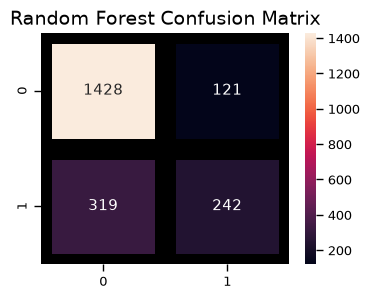

In [82]:
plt.figure(figsize=(4,3))
sns.heatmap(
    confusion_matrix(
        y_test, pred_y_rf
    ), annot=True, fmt='d', linecolor='k', linewidths=14
)
plt.title("Random Forest Confusion Matrix", fontsize=14)
plt.show()

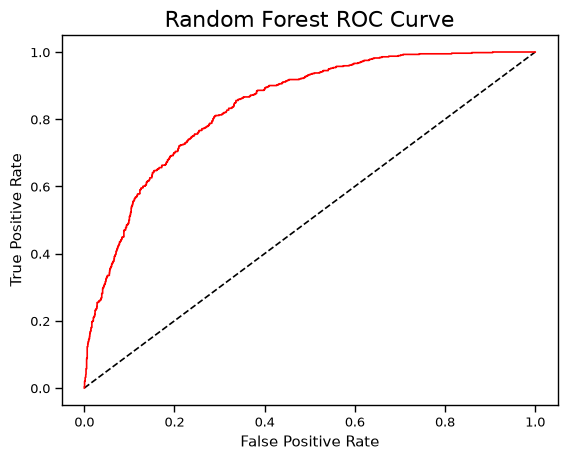

In [83]:
y_rf_pred_prob = model_rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, thresholds = roc_curve(y_test, y_rf_pred_prob)
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr_rf, tpr_rf, label="Random Forest", color='r')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve', fontsize=16)
plt.show()

In [84]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
accuracy_lr = lr_model.score(X_test, y_test)
print("Logistic Regression Accuracy is: ", accuracy_lr)

Logistic Regression Accuracy is:  0.8042654028436019


In [85]:
lr_pred = lr_model.predict(X_test)
report = classification_report(y_test, lr_pred)
print(report)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1549
           1       0.65      0.56      0.60       561

    accuracy                           0.80      2110
   macro avg       0.75      0.73      0.74      2110
weighted avg       0.80      0.80      0.80      2110



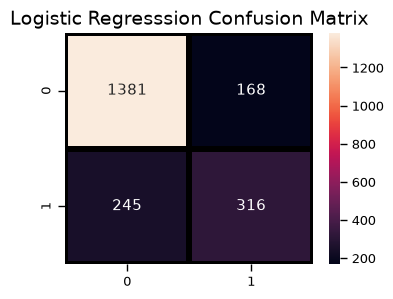

In [86]:
plt.figure(figsize=(4,3))
sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True, fmt='d',linecolor='k', linewidths=3
)
plt.title("Logistic Regresssion Confusion Matrix", fontsize=14)
plt.show()

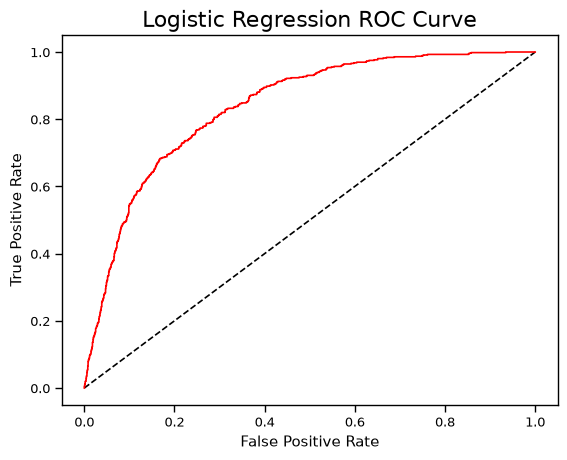

In [87]:
y_pred_prob = lr_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr, label='LogisticRegression', color='r')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression ROC Curve', fontsize=16)
plt.show()

In [88]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
accuracy_dt = dt_model.score(X_test, y_test)
print("Decision Tree accuracy is: ", accuracy_dt)

Decision Tree accuracy is:  0.7109004739336493


In [89]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80      1549
           1       0.46      0.49      0.47       561

    accuracy                           0.71      2110
   macro avg       0.63      0.64      0.64      2110
weighted avg       0.72      0.71      0.71      2110



In [91]:
a_model = AdaBoostClassifier()
a_model.fit(X_train, y_train)
a_preds = a_model.predict(X_test)
accuracy_a = accuracy_score(y_test, a_preds)
print("AdaBoost Classifier Accuracy: ", accuracy_a)

AdaBoost Classifier Accuracy:  0.7928909952606635


In [92]:
print(classification_report(y_test, a_preds))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1549
           1       0.66      0.45      0.54       561

    accuracy                           0.79      2110
   macro avg       0.74      0.68      0.70      2110
weighted avg       0.78      0.79      0.78      2110



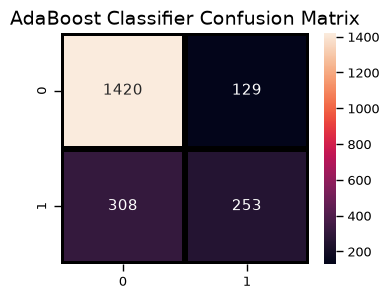

In [93]:
plt.figure(figsize=(4,3))
sns.heatmap(
    confusion_matrix(y_test, a_preds),
    annot=True, fmt='d', linecolor='k', linewidths=3
)
plt.title("AdaBoost Classifier Confusion Matrix", fontsize=14)
plt.show()

In [94]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
print("Gradient Boosting Classifer accuracy: ", accuracy_score(y_test, gb_pred))

Gradient Boosting Classifer accuracy:  0.7928909952606635


In [96]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1549
           1       0.64      0.50      0.56       561

    accuracy                           0.79      2110
   macro avg       0.74      0.70      0.71      2110
weighted avg       0.78      0.79      0.78      2110



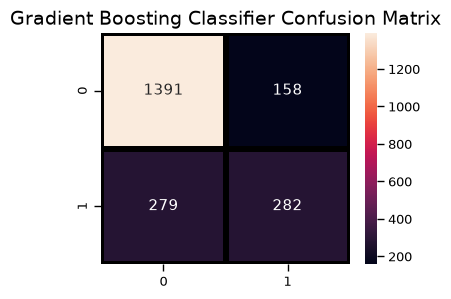

In [97]:
plt.figure(figsize=(4,3))
sns.heatmap(
    confusion_matrix(y_test, gb_pred),
    annot=True, fmt='d', linecolor='k', linewidths=3
)
plt.title("Gradient Boosting Classifier Confusion Matrix", fontsize=14)
plt.show()

In [98]:
from sklearn.ensemble import VotingClassifier

clf1 = GradientBoostingClassifier()
clf2 = LogisticRegression()
clf3 = AdaBoostClassifier()
eclf1 = VotingClassifier(
    estimators=[
        ('gbc', clf1), ('lr', clf2), ('abc', clf3)
    ],
    voting='soft',
)
eclf1.fit(X_train, y_train)
predictions = eclf1.predict(X_test)
print("Final Accuracy Score ")
print(accuracy_score(y_test, predictions))

Final Accuracy Score 
0.8023696682464455
